In [2]:
import glob
import h5py
from tqdm import tqdm
import numpy as np
from matplotlib import pyplot as plt
import os
import pandas as pd

In [10]:
def read_files(glob_pattern, minyear=0, maxyear=9999):
    files = glob.glob(glob_pattern)
    files.sort()
    times = []
    peaklats_n = []
    peaklats_s = []
    
    for fpath in tqdm(files):
        year = int(os.path.basename(fpath)[:4].split('_')[0])
        if year > maxyear:
            continue
        if year < minyear:
            continue

        times.append(pd.to_datetime(os.path.basename(fpath)[:-4].split('_')[0]))
        hdf = h5py.File(fpath)
        peaklats_n.append(hdf['peak_lat_north'][()].item())
        peaklats_s.append(hdf['peak_lat_south'][()].item())
        hdf.close()
    
    return np.array(times), np.array(peaklats_n), np.array(peaklats_s)

In [14]:
times_samples, peaklat_north_samples, peaklat_south_samples = read_files(
    '../data/validation/peaklat_samples/*.hdf5',
    maxyear=2017
)

100%|█████████████████████████████████████████████████████████████████████████████| 2748/2748 [00:01<00:00, 1435.73it/s]


In [15]:
times_testdata, peaklat_north_testdata, peaklat_south_testdata = read_files(
    '../data/validation/peaklat_testdata/*.hdf5',
    maxyear=2017
)

100%|█████████████████████████████████████████████████████████████████████████████| 5496/5496 [00:04<00:00, 1369.84it/s]


In [19]:
times_samples.size, times_testdata.size

(1999, 3998)

Text(0.5, 0.98, 'Latitudes of Peak Magnetic Field Strength at 1 $R_\\odot$')

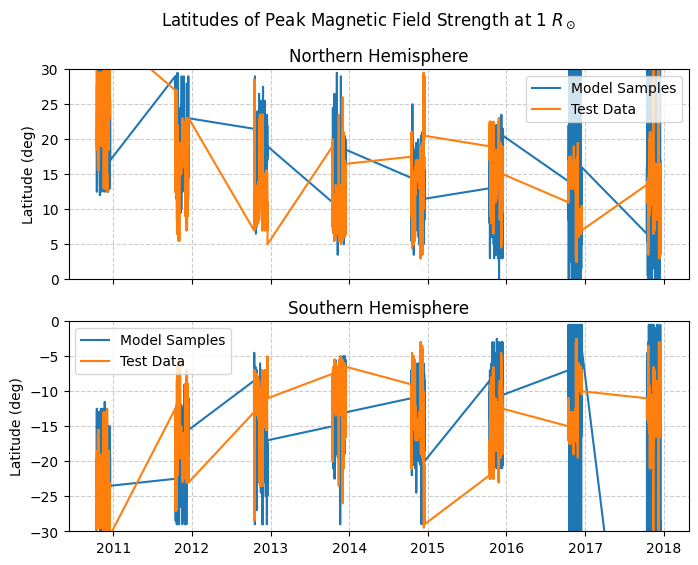

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(times_samples, peaklat_north_samples, label='Model Samples')
axes[0].plot(times_testdata, peaklat_north_testdata, label='Test Data')
axes[0].set_ylim(0, 30)
axes[0].legend()
axes[0].set_ylabel('Latitude (deg)')
axes[0].grid(linestyle='dashed', color='#ccc')
axes[0].set_title('Northern Hemisphere')

axes[1].plot(times_samples, peaklat_south_samples, label='Model Samples')
axes[1].plot(times_testdata, peaklat_south_testdata, label='Test Data')
axes[1].set_ylim(-30, 0)
axes[1].legend(loc='upper left')
axes[1].set_ylabel('Latitude (deg)')
axes[1].grid(linestyle='dashed', color='#ccc')
axes[1].set_title('Southern Hemisphere')


fig.suptitle(r'Latitudes of Peak Magnetic Field Strength at 1 $R_\odot$')

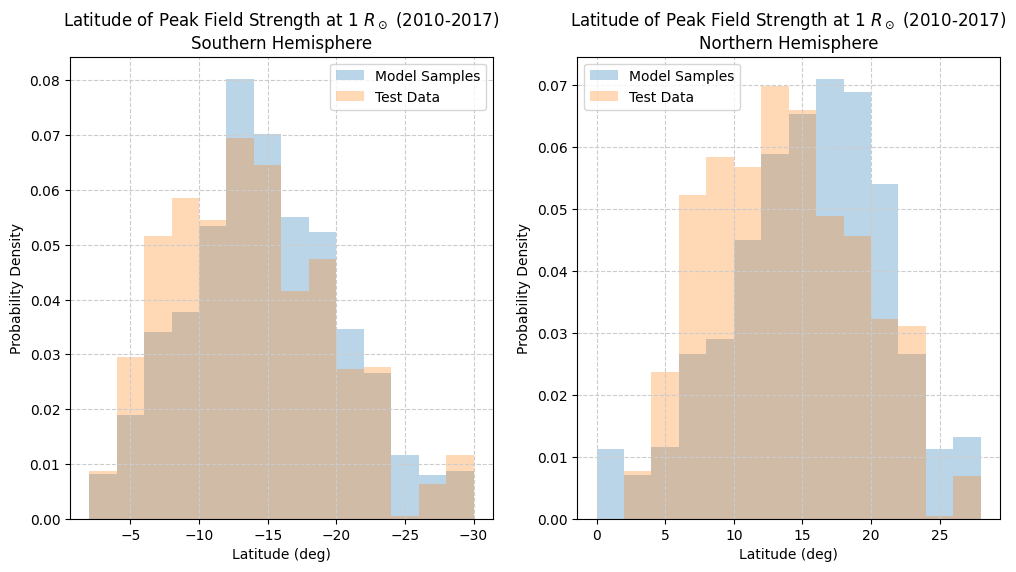

In [17]:
plt.figure(figsize=(12, 6))

bins = np.arange(-30, 0, 2)
plt.subplot(121)
plt.hist(peaklat_south_samples, bins=bins, label='Model Samples', density=True, alpha=0.3)
plt.hist(peaklat_south_testdata, bins=bins, label='Test Data', density=True, alpha=0.3)
plt.legend()
plt.title(r'Latitude of Peak Field Strength at 1 $R_\odot$ (2010-2017)' + '\nSouthern Hemisphere')
plt.ylabel('Probability Density')
plt.grid(color='#ccc', linestyle='dashed')
plt.xlabel('Latitude (deg)')
plt.xlim(plt.xlim()[::-1])

plt.subplot(122)
bins = np.arange(0, 30, 2)
plt.hist(peaklat_north_samples, bins=bins, label='Model Samples',density=True,  alpha=0.3)
plt.hist(peaklat_north_testdata, bins=bins, label='Test Data',density=True,  alpha=0.3)
plt.legend()
plt.title(r'Latitude of Peak Field Strength at 1 $R_\odot$ (2010-2017)' + '\nNorthern Hemisphere')
plt.ylabel('Probability Density')
plt.grid(color='#ccc', linestyle='dashed')
plt.xlabel('Latitude (deg)')

plt.savefig('../plots/paper/peaklat_hists.png', dpi=300)


In [18]:
print('North Samples')
print('-------------')
print('Mean: %.1f' % np.mean(peaklat_north_samples))
print('STD: %.1f' % np.std(peaklat_north_samples))
print()
print('North Test Data')
print('-------------')
print('Mean: %.1f' % np.mean(peaklat_north_testdata))
print('STD: %.1f' % np.std(peaklat_north_testdata))
print()
print('South Samples')
print('-------------')
print('Mean: %.1f' % np.mean(peaklat_south_samples))
print('STD: %.1f' % np.std(peaklat_south_samples))
print()
print('South Test Data')
print('-------------')
print('Mean: %.1f' % np.mean(peaklat_south_testdata))
print('STD: %.1f' % np.std(peaklat_south_testdata))

North Samples
-------------
Mean: 18.4
STD: 14.0

North Test Data
-------------
Mean: 14.4
STD: 6.6

South Samples
-------------
Mean: -17.1
STD: 12.6

South Test Data
-------------
Mean: -14.4
STD: 6.6


(29.4, -1.4000000000000001)

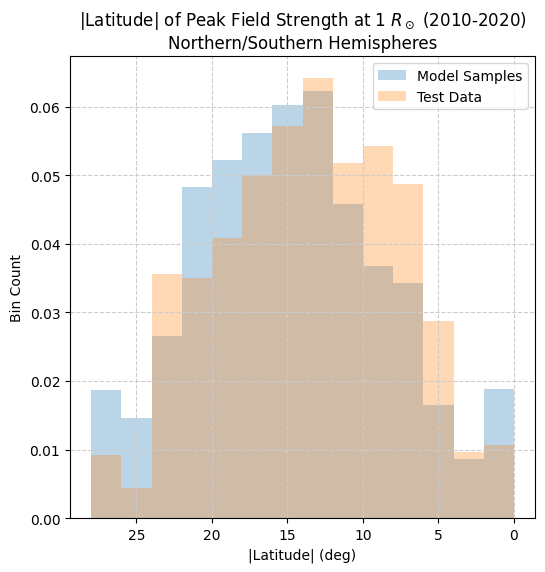

In [13]:
peaklat_abs_samples = np.array([-peaklat_south_samples, peaklat_north_samples]).flatten()
peaklat_abs_testdata = np.array([-peaklat_south_testdata, peaklat_north_testdata]).flatten()

plt.figure(figsize=(6, 6))

bins = np.arange(0, 30, 2)
plt.hist(peaklat_abs_samples, bins=bins, label='Model Samples', density=True, alpha=0.3)
plt.hist(peaklat_abs_testdata, bins=bins, label='Test Data', density=True, alpha=0.3)
plt.legend()
plt.title(r'|Latitude| of Peak Field Strength at 1 $R_\odot$ (2010-2020)' + '\nNorthern/Southern Hemispheres')
plt.ylabel('Bin Count')
plt.grid(color='#ccc', linestyle='dashed')
plt.xlabel('|Latitude| (deg)')
plt.xlim(plt.xlim()[::-1])


In [14]:
print('North Samples')
print('-------------')
print('Mean: %.1f' % np.mean(peaklat_abs_samples))
print('STD: %.1f' % np.std(peaklat_abs_samples))
print()
print('North Test Data')
print('-------------')
print('Mean: %.1f' % np.mean(peaklat_abs_testdata))
print('STD: %.1f' % np.std(peaklat_abs_testdata))

North Samples
-------------
Mean: 23.4
STD: 21.3

North Test Data
-------------
Mean: 20.0
STD: 18.1
